<a href="https://colab.research.google.com/github/siojzz/UTSDEEPLEARNING/blob/task3-dec/kode/task3_cluster/task3_dec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3 — Tahap 3: DEC, Pemilihan Konfigurasi Akhir, dan `cluster.csv`

**Ruang lingkup.** Tahap ini menjalankan *Deep Embedded Clustering* (DEC) pada daftar calon (representasi × jumlah klaster) dari tahap 2b, membandingkannya dengan K-Means, GMM, dan *agglomerative*, lalu memilih konfigurasi akhir dengan aturan yang ditetapkan sebelum melihat hasil, dan menulis `cluster.csv`.

**Metode.** DEC bekerja di atas embedding tetap dari tahap 1. Embedding (distandarkan per dimensi) dimampatkan oleh *autoencoder* MLP menjadi kode 16 dimensi; K-Means pada kode itu memberi pusat awal; lalu encoder dan pusat dilatih meminimalkan KL(P‖Q), dengan Q kemiripan Student-t antara kode dan pusat, dan P distribusi target yang mempertajam penugasan berkeyakinan tinggi. Pelatihan berhenti bila kurang dari 0,1% label berubah antar putaran. Dua varian dijalankan: **DEC** murni, dan **DEC+rek** yang menambahkan kerugian rekonstruksi berbobot 0,1 (gaya IDEC) untuk mencegah ruang laten rusak pada data berstruktur lemah.

**Aturan pemilihan (ditetapkan sebelum eksperimen).**
1. Jumlah klaster akhir = **k\*** dari tahap 2b (puncak kesepakatan klaster antara gambar dan spektrum), kecuali ditentukan lain secara eksplisit pada sel konfigurasi. Calon pada k lain dilaporkan sebagai uji kepekaan.
2. Pada k akhir, konfigurasi dengan NMI terhadap mikroskop di atas 0,05 atau klaster terkecil di bawah 2% data dikeluarkan.
3. Sisanya diberi peringkat (rerata peringkat silhouette, Davies-Bouldin, keseimbangan modalitas), tiga teratas diuji kestabilannya dengan empat seed, dan pemenang ditentukan dari rerata peringkat keempat ukuran itu. Pelabelan yang diserahkan adalah seed yang paling mewakili (medoid menurut ARI antar seed).

**Alur.** 0 Persiapan → 1 Calon → 2 Menjalankan DEC → 3 Pemilihan akhir → 4 Perbandingan metode → 5 Profil klaster → 6 Visualisasi → 7 `cluster.csv` → 8 Kesimpulan → 9 Commit.

In [2]:
AKUN_GITHUB = 'siojzz'
EMAIL_GITHUB = 'sfyrian21@gmail.com'
FORK_TAHAP2B = 'https://github.com/rafiptrnto/UTSDEEPLEARNING.git'   # cadangan bila tahap 2b belum di-merge
CABANG_TAHAP2B = 'task3-lanjutan'

K_FINAL = None            # None: pakai k* dari tahap 2b
METODE = {'DEC': 0.0, 'DEC+rek': 0.1}     # nama -> bobot kerugian rekonstruksi
D_Z, EP_AE, ROUNDS = 16, 60, 40
SEED = 0
SEED_STAB = [1, 2, 3]
N_SIL = 8000
GERBANG_NMI_MIK = 0.05
UKURAN_MIN = 0.02
SPEKTRUM_REF = ['ae_spektrum', 'pca_spektrum']
GAMBAR_REF = ['ae_gambar', 'simclr_gambar']

import torch, numpy, pandas, sklearn, sys, warnings, time, json, os
warnings.filterwarnings('ignore')
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", numpy.__version__, "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
print("GPU tersedia:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Aktifkan GPU dulu: Runtime -> Change runtime type -> T4 GPU"
dev = 'cuda'

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
GPU tersedia: True


In [3]:
if not os.path.exists('/content/data/clustering.npz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
from google.colab import userdata
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git checkout main
!git pull --no-edit upstream main
if not os.path.exists('kode/task3_cluster/serah_terima_v2/serah_terima_v2.json'):
    print("Serah-terima tahap 2b belum ada di main; mencoba branch tahap 2b pada fork mitra...")
    !git pull --no-edit {FORK_TAHAP2B} {CABANG_TAHAP2B}
assert os.path.exists('kode/task3_cluster/serah_terima_v2/serah_terima_v2.json'), "Hasil tahap 2b belum tersedia. Minta mitra merge PR tahap 2b."
!git checkout -B task3-dec
!ls kode/task3_cluster kode/task3_cluster/serah_terima_v2

Downloading...
From (original): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb
From (redirected): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb&confirm=t&uuid=4d111c2e-8538-4672-bdc0-1920876f291e
To: /content/data_uts_dl.zip
100% 396M/396M [00:02<00:00, 135MB/s]
Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 220, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 220 (delta 5), reused 18 (delta 0), pack-reused 175 (from 2)
Receiving objects: 100% (220/220), 69.13 MiB | 35.90 MiB/s, done.
Resolving deltas: 100% (53/53), done.
/content/UTSDEEPLEARNING
Already on 'main'
Your branch is up to date with 'origin/main'.
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 37 (delta 10), reused 29 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (37/37), 305.22 KiB | 5

### Kode pendukung

| Berkas | Isi |
|---|---|
| `clu_cluster.py` | diperbarui: `ukuran_label` (ukuran mutu untuk label sembarang) dan `kestabilan_label` (ARI antar seed dan medoid); fungsi lama tidak berubah |
| `clu_dec.py` | *autoencoder* MLP pada embedding, kemiripan Student-t, distribusi target, dan putaran DEC dengan pusat awal dari K-Means |

In [4]:
%%writefile /content/UTSDEEPLEARNING/kode/task3_cluster/clu_cluster.py
"""Pengelompokan klasik dan kriteria jumlah klaster untuk Task 3 (tahap 2). Tanpa PyTorch."""
import json, numpy as np, pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)


def muat_emb(folder):
    man = json.load(open(f'{folder}/manifest.json'))
    emb = {k: np.load(f'{folder}/{k}.npy').astype(np.float32) for k in man['embedding']}
    return emb, man


def kmeans(emb, k, seed=0, n_init=3):
    return KMeans(k, n_init=n_init, random_state=seed).fit(emb)


def gmm_label(emb, k, d_pca=16, seed=0):
    """GMM kovarians diagonal pada PCA d_pca dimensi. Mengembalikan (label, BIC)."""
    z = PCA(min(d_pca, emb.shape[1]), random_state=seed).fit_transform(emb)
    g = GaussianMixture(k, covariance_type='diag', n_init=2, reg_covar=1e-4, random_state=seed).fit(z)
    return g.predict(z), float(g.bic(z))


def aglo_prototipe(emb, k, n_proto=600, seed=0):
    """Agglomerative (Ward) pada n_proto prototipe K-Means, lalu tiap sampel mengikuti prototipenya.
    Ward langsung pada 36.000 sampel memerlukan matriks jarak terlalu besar."""
    km = KMeans(min(n_proto, len(emb) // 5), n_init=1, random_state=seed).fit(emb)
    lab_p = AgglomerativeClustering(k, linkage='ward').fit_predict(km.cluster_centers_)
    return lab_p[km.labels_]


def kestabilan(emb, k, ulang=3, seed=0, frac=0.5):
    """ARI antar dua K-Means yang dilatih pada separuh sampel acak berbeda, keduanya memberi label seluruh data."""
    rng = np.random.RandomState(seed)
    r = []
    for _ in range(ulang):
        p = rng.permutation(len(emb))
        a, b = p[:int(len(emb) * frac)], p[int(len(emb) * frac):]
        ka, kb = KMeans(k, n_init=2, random_state=int(rng.randint(1e6))).fit(emb[a]), KMeans(k, n_init=2, random_state=int(rng.randint(1e6))).fit(emb[b])
        r.append(adjusted_rand_score(ka.predict(emb), kb.predict(emb)))
    return float(np.mean(r))


def kriteria_k(emb, ks, n_sil=8000, seed=0, d_pca=16):
    """Per k: inersia, silhouette (sub-sampel), Davies-Bouldin, Calinski-Harabasz, BIC GMM, kestabilan."""
    rng = np.random.RandomState(seed)
    isub = rng.choice(len(emb), min(n_sil, len(emb)), replace=False)
    out = []
    for k in ks:
        km = kmeans(emb, k, seed)
        _, bic = gmm_label(emb, k, d_pca, seed)
        out.append(dict(k=int(k), inersia=float(km.inertia_),
                        silhouette=float(silhouette_score(emb[isub], km.labels_[isub])),
                        dbi=float(davies_bouldin_score(emb, km.labels_)),
                        ch=float(calinski_harabasz_score(emb, km.labels_)),
                        bic=bic, kestabilan=kestabilan(emb, k, seed=seed)))
    return pd.DataFrame(out)


def k_pilihan(df, ambang_stab=0.8):
    """k yang dipilih tiap kriteria. Kestabilan: k terbesar dengan ARI >= ambang (bila tak ada: k dengan ARI tertinggi).
    Konsensus: median dari empat kriteria, dibulatkan."""
    p = dict(silhouette=int(df.loc[df.silhouette.idxmax(), 'k']),
             dbi=int(df.loc[df.dbi.idxmin(), 'k']),
             bic=int(df.loc[df.bic.idxmin(), 'k']))
    ok = df[df.kestabilan >= ambang_stab]
    p['kestabilan'] = int(ok.k.max()) if len(ok) else int(df.loc[df.kestabilan.idxmax(), 'k'])
    p['konsensus'] = int(round(float(np.median([p['silhouette'], p['dbi'], p['bic'], p['kestabilan']]))))
    return p


def uji_mikroskop(label, mik):
    """ARI dan NMI klaster terhadap mikroskop (dekat 0 = klaster tidak mengikuti alat) serta kemurnian mikroskop terbesar."""
    mik = np.asarray(mik).astype(str)
    lab = np.asarray(label)
    ms = np.unique(mik)
    murni = 0.0
    for c in np.unique(lab):
        i = lab == c
        murni += max((mik[i] == m).sum() for m in ms)
    return dict(ari=float(adjusted_rand_score(mik, lab)), nmi=float(normalized_mutual_info_score(mik, lab)),
                kemurnian=float(murni / len(lab)), mayoritas=float(max((mik == m).mean() for m in ms)))


def ukuran_pada_k(emb, k, mik, seed=0, n_sil=8000):
    km = kmeans(emb, k, seed)
    rng = np.random.RandomState(seed)
    isub = rng.choice(len(emb), min(n_sil, len(emb)), replace=False)
    u = uji_mikroskop(km.labels_, mik)
    return dict(silhouette=float(silhouette_score(emb[isub], km.labels_[isub])), dbi=float(davies_bouldin_score(emb, km.labels_)),
                kestabilan=kestabilan(emb, k, seed=seed), mik_nmi=u['nmi'], mik_ari=u['ari'], mik_kemurnian=u['kemurnian'],
                ukuran_min=float(np.bincount(km.labels_).min() / len(emb))), km


def peringkat_gabungan(df):
    """Rerata peringkat: silhouette tinggi, DBI rendah, kestabilan tinggi, NMI mikroskop rendah."""
    r = pd.DataFrame({'silhouette': df.silhouette.rank(ascending=False), 'dbi': df.dbi.rank(ascending=True),
                      'kestabilan': df.kestabilan.rank(ascending=False), 'mik_nmi': df.mik_nmi.rank(ascending=True)}, index=df.index)
    return r.mean(1)


def kesesuaian_modalitas(ea, eb, ks=range(2, 9), seed=0):
    """Kesepakatan pengelompokan dari dua modalitas: ARI dan NMI antara K-Means pada embedding A dan pada embedding B,
    untuk tiap k. Nilai dasar (permutasi label B) mendekati 0."""
    rng = np.random.RandomState(seed)
    out = []
    for k in ks:
        la, lb = kmeans(ea, k, seed).labels_, kmeans(eb, k, seed).labels_
        out.append(dict(k=int(k), ari=float(adjusted_rand_score(la, lb)), nmi=float(normalized_mutual_info_score(la, lb)),
                        ari_acak=float(adjusted_rand_score(la, rng.permutation(lb)))))
    return pd.DataFrame(out)


def kontribusi_modalitas(lab, refs_g, refs_s):
    """NMI label terhadap klaster satu-modalitas: rata-rata atas referensi gambar dan atas referensi spektrum."""
    g = float(np.mean([normalized_mutual_info_score(lab, r) for r in refs_g]))
    s = float(np.mean([normalized_mutual_info_score(lab, r) for r in refs_s]))
    return g, s


def evaluasi_rep_k(emb, k, mik, refs_g, refs_s, seed=0, n_sil=8000):
    """Mutu K-Means pada satu k, diagnosis mikroskop, dan seberapa seimbang klaster mewakili gambar dan spektrum."""
    u, km = ukuran_pada_k(emb, k, mik, seed, n_sil)
    g, s = kontribusi_modalitas(km.labels_, refs_g, refs_s)
    u.update(nmi_gambar=g, nmi_spektrum=s, seimbang=min(g, s))
    return u, km


def peringkat_k_tetap(df):
    """Rerata peringkat pada k tetap: silhouette tinggi, DBI rendah, kestabilan tinggi, keseimbangan modalitas tinggi."""
    r = pd.DataFrame({'silhouette': df.silhouette.rank(ascending=False), 'dbi': df.dbi.rank(ascending=True),
                      'kestabilan': df.kestabilan.rank(ascending=False), 'seimbang': df.seimbang.rank(ascending=False)}, index=df.index)
    return r.mean(1)


def ukuran_label(emb, lab, mik, refs_g, refs_s, lab_dasar=None, seed=0, n_sil=8000):
    """Ukuran mutu untuk label sembarang (K-Means, GMM, DEC, ...) pada ruang embedding asal."""
    lab = np.asarray(lab)
    rng = np.random.RandomState(seed)
    isub = rng.choice(len(emb), min(n_sil, len(emb)), replace=False)
    ada = len(np.unique(lab[isub])) > 1
    u = uji_mikroskop(lab, mik)
    g, s = kontribusi_modalitas(lab, refs_g, refs_s)
    out = dict(k_efektif=int(len(np.unique(lab))), ukuran_min=float(np.bincount(lab).min() / len(lab)),
               silhouette=float(silhouette_score(emb[isub], lab[isub])) if ada else float('nan'),
               dbi=float(davies_bouldin_score(emb, lab)) if len(np.unique(lab)) > 1 else float('nan'),
               mik_nmi=u['nmi'], mik_ari=u['ari'], nmi_gambar=g, nmi_spektrum=s, seimbang=min(g, s))
    if lab_dasar is not None:
        out['ari_vs_kmeans'] = float(adjusted_rand_score(lab, lab_dasar))
    return out


def kestabilan_label(daftar_label):
    """Rerata ARI berpasangan antar beberapa pelabelan, dan indeks pelabelan paling 'tengah' (medoid)."""
    n = len(daftar_label)
    if n < 2:
        return float('nan'), 0
    M = np.eye(n)
    for i in range(n):
        for j in range(i + 1, n):
            M[i, j] = M[j, i] = adjusted_rand_score(daftar_label[i], daftar_label[j])
    rata = (M.sum(1) - 1) / (n - 1)
    return float(((M.sum() - n) / (n * (n - 1)))), int(np.argmax(rata))


Overwriting /content/UTSDEEPLEARNING/kode/task3_cluster/clu_cluster.py


In [5]:
%%writefile /content/UTSDEEPLEARNING/kode/task3_cluster/clu_dec.py
"""Deep Embedded Clustering (DEC) di atas embedding tetap dari tahap 1.
Alur: autoencoder MLP pada embedding -> K-Means pada kode laten -> penyulingan dengan KL(P||Q)."""
import copy, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.cluster import KMeans


def atur_seed(seed):
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class AEEmb(nn.Module):
    def __init__(self, d_in, d_z=16, h=256):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Linear(h, 128), nn.ReLU(), nn.Linear(128, d_z))
        self.dec = nn.Sequential(nn.Linear(d_z, 128), nn.ReLU(), nn.Linear(128, h), nn.ReLU(), nn.Linear(h, d_in))

    def forward(self, x):
        z = self.enc(x)
        return z, self.dec(z)


def latih_ae(x, d_z=16, epoch=60, bs=256, lr=1e-3, noise=0.1, seed=0):
    """x: tensor (N,D) di GPU, sudah distandarkan per dimensi."""
    atur_seed(seed)
    ae = AEEmb(x.shape[1], d_z).to(x.device)
    opt = torch.optim.Adam(ae.parameters(), lr=lr)
    n = x.shape[0]
    riwayat = []
    for ep in range(epoch):
        ae.train()
        perm = torch.randperm(n, device=x.device)
        tot, m = 0.0, 0
        for i in range(0, n - bs + 1, bs):
            xb = x[perm[i:i + bs]]
            _, rec = ae(xb + noise * torch.randn_like(xb))
            loss = F.mse_loss(rec, xb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.item(); m += 1
        riwayat.append(tot / max(m, 1))
    return ae, riwayat


@torch.no_grad()
def kode(ae, x, bs=4096):
    ae.eval()
    return torch.cat([ae.enc(x[i:i + bs]) for i in range(0, x.shape[0], bs)])


def soft_assign(z, mu, alpha=1.0):
    d2 = ((z.unsqueeze(1) - mu.unsqueeze(0)) ** 2).sum(-1)
    q = (1.0 + d2 / alpha) ** (-(alpha + 1.0) / 2.0)
    return q / q.sum(1, keepdim=True)


def target(q):
    w = q ** 2 / q.sum(0, keepdim=True)
    return w / w.sum(1, keepdim=True)


def init_kmeans(z, k, seed=0, n_init=20):
    km = KMeans(k, n_init=n_init, random_state=seed).fit(z.cpu().numpy())
    return km.cluster_centers_.astype(np.float32), km.labels_


def dec(x, ae0, k, gamma=0.0, rounds=40, lr=1e-3, bs=256, tol=0.001, seed=0):
    """Menjalankan DEC dari autoencoder terlatih ae0 (tidak diubah; disalin).
    gamma > 0 menambahkan regulasi rekonstruksi (gaya IDEC). Mengembalikan (label, kode, riwayat_perubahan, label_init)."""
    atur_seed(seed)
    ae = copy.deepcopy(ae0)
    mu0, lab_init = init_kmeans(kode(ae, x), k, seed)
    mu = nn.Parameter(torch.tensor(mu0, device=x.device))
    params = list(ae.enc.parameters()) + [mu] + (list(ae.dec.parameters()) if gamma > 0 else [])
    opt = torch.optim.Adam(params, lr=lr)
    n = x.shape[0]
    prev, riwayat = None, []
    for r in range(rounds):
        with torch.no_grad():
            z = kode(ae, x)
            q = soft_assign(z, mu)
            p = target(q)
            lab = q.argmax(1)
        if prev is not None:
            delta = (lab != prev).float().mean().item()
            riwayat.append(delta)
            if delta < tol:
                break
        prev = lab
        ae.train()
        perm = torch.randperm(n, device=x.device)
        for i in range(0, n - bs + 1, bs):
            b = perm[i:i + bs]
            zb = ae.enc(x[b])
            qb = soft_assign(zb, mu).clamp_min(1e-8)
            loss = F.kl_div(qb.log(), p[b], reduction='batchmean')
            if gamma > 0:
                loss = loss + gamma * F.mse_loss(ae.dec(zb), x[b])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    with torch.no_grad():
        z = kode(ae, x)
        lab = soft_assign(z, mu).argmax(1)
    return lab.cpu().numpy(), z.cpu().numpy(), riwayat, lab_init


Writing /content/UTSDEEPLEARNING/kode/task3_cluster/clu_dec.py


In [6]:
sys.path.insert(0, '/content/UTSDEEPLEARNING/kode/task3_cluster')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import importlib, clu_cluster, clu_dec
importlib.reload(clu_cluster); importlib.reload(clu_dec)
from clu_cluster import *
from clu_dec import latih_ae, dec
from IPython.display import display, Markdown
OUT = '/content/UTSDEEPLEARNING/kode/task3_cluster'
REPO = '/content/UTSDEEPLEARNING'
ST = f'{OUT}/serah_terima_v2'
INFO = {}

EMB, MAN = muat_emb(f'{OUT}/emb')
meta = pd.read_csv('/content/data/clustering_meta.csv')
if 'indeks' in meta.columns: meta = meta.sort_values('indeks').reset_index(drop=True)
mik = meta['mikroskop'].astype(str).values
assert all(len(e) == len(mik) for e in EMB.values())
SERAH = json.load(open(f'{ST}/serah_terima_v2.json'))

## 1. Calon dari tahap 2b

Daftar calon (representasi × k) beserta label K-Means awalnya dibaca dari `serah_terima_v2.json`. Label K-Means itu dipakai sebagai pembanding (metode klasik) dan untuk menghitung seberapa jauh DEC mengubah pembagian.

In [7]:
CAND = SERAH['calon']
K_STAR = int(SERAH['k_star'])
K_AKHIR = int(K_FINAL) if K_FINAL is not None else K_STAR
print("k* dari tahap 2b:", K_STAR, "| k akhir yang dipakai:", K_AKHIR, "| himpunan k calon:", SERAH['k_set'])
display(pd.DataFrame(CAND)[['representasi', 'k', 'peringkat', 'silhouette', 'kestabilan', 'seimbang', 'mik_nmi']].round(3))
INFO.update(k_star=K_STAR, k_akhir=K_AKHIR, k_set=SERAH['k_set'], n_calon=len(CAND))

k* dari tahap 2b: 9 | k akhir yang dipakai: 9 | himpunan k calon: [7, 9, 11]


,representasi,k,peringkat,silhouette,kestabilan,seimbang,mik_nmi
0,fusi_simclr_concat,7,1.50,0.164,0.855,0.411,0.025
1,fusi_gabungan,7,3.25,0.104,0.846,0.343,0.000
2,pca_spektrum,7,4.25,0.182,0.520,0.212,0.000
3,fusi_simclr_concat,9,1.75,0.156,0.901,0.446,0.049
4,fusi_gabungan,9,3.00,0.090,0.887,0.419,0.000
5,pca_spektrum,9,3.25,0.185,0.717,0.285,0.000
6,fusi_gabungan,11,2.25,0.088,0.780,0.413,0.000
7,pca_spektrum,11,2.75,0.178,0.694,0.296,0.000
8,ae_spektrum,11,3.25,0.118,0.688,0.338,0.000


## 2. Menjalankan DEC pada semua calon

Untuk tiap representasi, *autoencoder* dilatih sekali (seed 0, 60 epoch, derau masukan 0,1). Untuk tiap calon (representasi, k) dan tiap varian dijalankan DEC. Semua ukuran dihitung pada ruang embedding asal (bukan ruang laten DEC) agar sebanding dengan K-Means. **Keseimbangan modalitas** adalah NMI label dengan klaster gambar-saja dan dengan klaster spektrum-saja (K-Means pada embedding gambar dan embedding spektrum dengan k yang sama), dan yang terkecil dari keduanya; ini heuristik yang mengandaikan satu kelompok laten memengaruhi kedua modalitas.

In [8]:
X, AE = {}, {}
def ambil_x(rep):
    if rep not in X:
        e = EMB[rep]; e = (e - e.mean(0)) / (e.std(0) + 1e-6)
        X[rep] = torch.from_numpy(e.astype(np.float32)).to(dev)
    return X[rep]

def ambil_ae(rep, seed):
    if (rep, seed) not in AE:
        t = time.time()
        AE[(rep, seed)], rw = latih_ae(ambil_x(rep), D_Z, EP_AE, seed=seed)
        print(f"  AE {rep} seed {seed}: MSE rekonstruksi {rw[-1]:.3f} | {time.time() - t:.0f} dtk")
    return AE[(rep, seed)]

def jalankan(rep, k, metode, seed):
    lab, z, rw, lab_init = dec(ambil_x(rep), ambil_ae(rep, seed), k, gamma=METODE[metode], rounds=ROUNDS, seed=seed)
    return lab.astype(int), len(rw) + 1

REFS = {}
def ambil_refs(k):
    if k not in REFS:
        REFS[k] = ([kmeans(EMB[n], k, SEED).labels_ for n in GAMBAR_REF], [kmeans(EMB[n], k, SEED).labels_ for n in SPEKTRUM_REF])
    return REFS[k]

RUNS, BARIS = {}, []
t0 = time.time()
for c in CAND:
    rep, k = c['representasi'], int(c['k'])
    dasar = np.load(f"{ST}/{c['label']}").astype(int)
    rg, rs = ambil_refs(k)
    RUNS[(rep, k, 'K-Means', SEED)] = dasar
    BARIS.append(dict(representasi=rep, k=k, metode='K-Means', putaran=0, **ukuran_label(EMB[rep], dasar, mik, rg, rs, lab_dasar=dasar, seed=SEED, n_sil=N_SIL)))
    for m in METODE:
        lab, put = jalankan(rep, k, m, SEED)
        RUNS[(rep, k, m, SEED)] = lab
        BARIS.append(dict(representasi=rep, k=k, metode=m, putaran=put, **ukuran_label(EMB[rep], lab, mik, rg, rs, lab_dasar=dasar, seed=SEED, n_sil=N_SIL)))
    print(f"{rep} k={k} selesai | {time.time() - t0:.0f} dtk")
TAB = pd.DataFrame(BARIS)
TAB.to_csv(f'{OUT}/hasil/dec_semua_calon.csv', index=False)
display(TAB[['representasi', 'k', 'metode', 'putaran', 'k_efektif', 'ukuran_min', 'silhouette', 'dbi', 'mik_nmi', 'seimbang', 'ari_vs_kmeans']].round(3))
INFO['tabel_calon'] = TAB.to_dict('records')

  AE fusi_simclr_concat seed 0: MSE rekonstruksi 0.046 | 25 dtk
fusi_simclr_concat k=7 selesai | 45 dtk
  AE fusi_gabungan seed 0: MSE rekonstruksi 0.154 | 18 dtk
fusi_gabungan k=7 selesai | 78 dtk
  AE pca_spektrum seed 0: MSE rekonstruksi 0.049 | 18 dtk
pca_spektrum k=7 selesai | 119 dtk
fusi_simclr_concat k=9 selesai | 148 dtk
fusi_gabungan k=9 selesai | 165 dtk
pca_spektrum k=9 selesai | 196 dtk
fusi_gabungan k=11 selesai | 238 dtk
pca_spektrum k=11 selesai | 289 dtk
  AE ae_spektrum seed 0: MSE rekonstruksi 0.035 | 19 dtk
ae_spektrum k=11 selesai | 347 dtk


,representasi,k,metode,putaran,k_efektif,ukuran_min,silhouette,dbi,mik_nmi,seimbang,ari_vs_kmeans
0,fusi_simclr_concat,7,K-Means,0,7,0.035,0.164,1.838,0.025,0.411,1.000
1,fusi_simclr_concat,7,DEC,16,7,0.061,0.140,3.198,0.000,0.367,0.574
2,fusi_simclr_concat,7,DEC+rek,17,7,0.062,0.139,3.210,0.000,0.365,0.572
3,fusi_gabungan,7,K-Means,0,7,0.119,0.104,2.153,0.000,0.343,1.000
4,fusi_gabungan,7,DEC,13,7,0.077,0.143,3.354,0.000,0.417,0.493
5,fusi_gabungan,7,DEC+rek,13,7,0.079,0.143,3.351,0.000,0.417,0.493
6,pca_spektrum,7,K-Means,0,7,0.112,0.182,1.593,0.000,0.212,1.000
7,pca_spektrum,7,DEC,21,7,0.018,0.119,4.499,0.000,0.354,0.314
8,pca_spektrum,7,DEC+rek,24,7,0.018,0.119,4.433,0.000,0.357,0.313
9,fusi_simclr_concat,9,K-Means,0,9,0.035,0.156,2.018,0.049,0.446,1.000


## 3. Pemilihan konfigurasi akhir

Aturan pada pendahuluan diterapkan pada k akhir. Tiga teratas menurut rerata peringkat (silhouette, Davies-Bouldin, keseimbangan modalitas) diuji kestabilannya: setiap seed melatih ulang *autoencoder* dan DEC dari awal (K-Means untuk konfigurasi K-Means), lalu dihitung rerata ARI berpasangan antar empat seed. Pemenang ditentukan dari rerata peringkat empat ukuran: silhouette, Davies-Bouldin, keseimbangan modalitas, dan kestabilan.

In [9]:
d = TAB[TAB.k == K_AKHIR].copy()
d['lolos'] = (d.mik_nmi <= GERBANG_NMI_MIK) & (d.ukuran_min >= UKURAN_MIN) & d.silhouette.notna()
print(f"calon pada k = {K_AKHIR}: {len(d)} | lolos gerbang: {int(d.lolos.sum())}")
if d.lolos.sum() == 0:
    print("Tidak ada yang lolos gerbang; semua calon dipertimbangkan (dicatat di kesimpulan).")
    d['lolos'] = True; INFO['gerbang_dilonggarkan'] = True
dl = d[d.lolos].copy()
dl['peringkat_awal'] = pd.DataFrame({'s': dl.silhouette.rank(ascending=False), 'd': dl.dbi.rank(ascending=True), 'b': dl.seimbang.rank(ascending=False)}).mean(1)
dl = dl.sort_values('peringkat_awal')
display(dl[['representasi', 'metode', 'silhouette', 'dbi', 'seimbang', 'mik_nmi', 'ukuran_min', 'peringkat_awal']].round(3))
UJI = dl.head(3)[['representasi', 'metode']].values.tolist()
print("diuji kestabilannya:", UJI)

STAB, SEEDLAB = [], {}
t0 = time.time()
for rep, m in UJI:
    daftar = [RUNS[(rep, K_AKHIR, m, SEED)]]
    for s in SEED_STAB:
        if m == 'K-Means': lab = kmeans(EMB[rep], K_AKHIR, s).labels_.astype(int)
        else: lab, _ = jalankan(rep, K_AKHIR, m, s)
        RUNS[(rep, K_AKHIR, m, s)] = lab
        daftar.append(lab)
    rata, med = kestabilan_label(daftar)
    SEEDLAB[(rep, m)] = (daftar, med)
    STAB.append(dict(representasi=rep, metode=m, kestabilan_seed=rata, seed_medoid=([SEED] + SEED_STAB)[med]))
    print(f"{rep} / {m}: kestabilan antar seed (ARI) {rata:.3f} | {time.time() - t0:.0f} dtk")
ST_DF = pd.DataFrame(STAB)
top = dl.head(3).merge(ST_DF, on=['representasi', 'metode'])
top['peringkat_akhir'] = pd.DataFrame({'s': top.silhouette.rank(ascending=False), 'd': top.dbi.rank(ascending=True),
                                       'b': top.seimbang.rank(ascending=False), 'k': top.kestabilan_seed.rank(ascending=False)}).mean(1)
top = top.sort_values(['peringkat_akhir', 'peringkat_awal']).reset_index(drop=True)
display(top[['representasi', 'metode', 'silhouette', 'dbi', 'seimbang', 'kestabilan_seed', 'peringkat_akhir']].round(3))
MENANG = top.iloc[0]
FINAL = dict(representasi=MENANG.representasi, metode=MENANG.metode, k=K_AKHIR)
daftar, med = SEEDLAB[(FINAL['representasi'], FINAL['metode'])]
LABEL_FINAL = daftar[med].astype(int)
print("KONFIGURASI AKHIR:", FINAL, "| seed medoid:", ([SEED] + SEED_STAB)[med], "| kestabilan antar seed:", round(float(MENANG.kestabilan_seed), 3))
INFO['final'] = dict(**FINAL, kestabilan_seed=float(MENANG.kestabilan_seed), seed_medoid=([SEED] + SEED_STAB)[med],
                     silhouette=float(MENANG.silhouette), dbi=float(MENANG.dbi), seimbang=float(MENANG.seimbang), mik_nmi=float(MENANG.mik_nmi))
INFO['uji_stabilitas'] = top.round(4).to_dict('records')

calon pada k = 9: 9 | lolos gerbang: 7


,representasi,metode,silhouette,dbi,seimbang,mik_nmi,ukuran_min,peringkat_awal
9,fusi_simclr_concat,K-Means,0.156,2.018,0.446,0.049,0.035,2.333
15,pca_spektrum,K-Means,0.185,1.475,0.285,0.000,0.090,3.000
14,fusi_gabungan,DEC+rek,0.137,3.682,0.465,0.000,0.056,3.667
13,fusi_gabungan,DEC,0.136,3.686,0.466,0.000,0.055,4.000
10,fusi_simclr_concat,DEC,0.122,3.332,0.421,0.028,0.043,4.667
11,fusi_simclr_concat,DEC+rek,0.121,3.328,0.420,0.028,0.044,5.000
12,fusi_gabungan,K-Means,0.090,2.241,0.419,0.000,0.086,5.333


diuji kestabilannya: [['fusi_simclr_concat', 'K-Means'], ['pca_spektrum', 'K-Means'], ['fusi_gabungan', 'DEC+rek']]
fusi_simclr_concat / K-Means: kestabilan antar seed (ARI) 0.962 | 2 dtk
pca_spektrum / K-Means: kestabilan antar seed (ARI) 0.883 | 4 dtk
  AE fusi_gabungan seed 1: MSE rekonstruksi 0.154 | 19 dtk
  AE fusi_gabungan seed 2: MSE rekonstruksi 0.153 | 18 dtk
  AE fusi_gabungan seed 3: MSE rekonstruksi 0.155 | 18 dtk
fusi_gabungan / DEC+rek: kestabilan antar seed (ARI) 0.822 | 91 dtk


,representasi,metode,silhouette,dbi,seimbang,kestabilan_seed,peringkat_akhir
0,fusi_simclr_concat,K-Means,0.156,2.018,0.446,0.962,1.75
1,pca_spektrum,K-Means,0.185,1.475,0.285,0.883,1.75
2,fusi_gabungan,DEC+rek,0.137,3.682,0.465,0.822,2.50


KONFIGURASI AKHIR: {'representasi': 'fusi_simclr_concat', 'metode': 'K-Means', 'k': 9} | seed medoid: 1 | kestabilan antar seed: 0.962


## 4. Perbandingan metode pada konfigurasi akhir

Pada representasi dan k terpilih, dibandingkan lima pembagian: K-Means, GMM (diagonal pada PCA 16 dimensi), *agglomerative* Ward (pada 600 prototipe), DEC, dan DEC+rek. Disajikan ukuran mutu internal, ketergantungan pada mikroskop, serta kesesuaian antar metode (ARI).

In [10]:
rep, k = FINAL['representasi'], FINAL['k']
rg, rs = ambil_refs(k)
dasar = RUNS[(rep, k, 'K-Means', SEED)]
PEMB = {'K-Means': dasar,
        'GMM': gmm_label(EMB[rep], k, seed=SEED)[0].astype(int),
        'Agglomerative (prototipe)': aglo_prototipe(EMB[rep], k, seed=SEED).astype(int)}
for m in METODE:
    PEMB[m] = RUNS[(rep, k, m, SEED)]
tab_m = pd.DataFrame({n: ukuran_label(EMB[rep], l, mik, rg, rs, lab_dasar=dasar, seed=SEED, n_sil=N_SIL) for n, l in PEMB.items()}).T
display(tab_m[['ukuran_min', 'silhouette', 'dbi', 'mik_nmi', 'seimbang']].astype(float).round(3))
nm = list(PEMB)
M = pd.DataFrame([[adjusted_rand_score(PEMB[a], PEMB[b]) for b in nm] for a in nm], index=nm, columns=nm)
display(M.round(3))
INFO['metode'] = dict(representasi=rep, k=k, ukuran=tab_m.astype(float).round(4).to_dict('index'), kesesuaian=M.round(4).to_dict())
tab_m.to_csv(f'{OUT}/hasil/dec_perbandingan_metode.csv'); M.to_csv(f'{OUT}/hasil/dec_kesesuaian_metode.csv')

,ukuran_min,silhouette,dbi,mik_nmi,seimbang
K-Means,0.035,0.156,2.018,0.049,0.446
GMM,0.035,0.127,2.400,0.041,0.451
Agglomerative (prototipe),0.001,0.150,2.465,0.000,0.438
DEC,0.043,0.122,3.332,0.028,0.421
DEC+rek,0.044,0.121,3.328,0.028,0.420


,K-Means,GMM,Agglomerative (prototipe),DEC,DEC+rek
K-Means,1.000,0.633,0.445,0.584,0.582
GMM,0.633,1.000,0.524,0.708,0.707
Agglomerative (prototipe),0.445,0.524,1.000,0.645,0.643
DEC,0.584,0.708,0.645,1.000,0.989
DEC+rek,0.582,0.707,0.643,0.989,1.000


## 5. Profil klaster

Klaster akhir dilihat pada data mentah: ukuran, komposisi mikroskop, spektrum rata-rata, dan contoh citra. Ini bukan bukti bahwa klaster sesuai kelompok material yang sebenarnya, tetapi memperlihatkan apakah klaster berbeda secara kasat mata pada kedua modalitas.

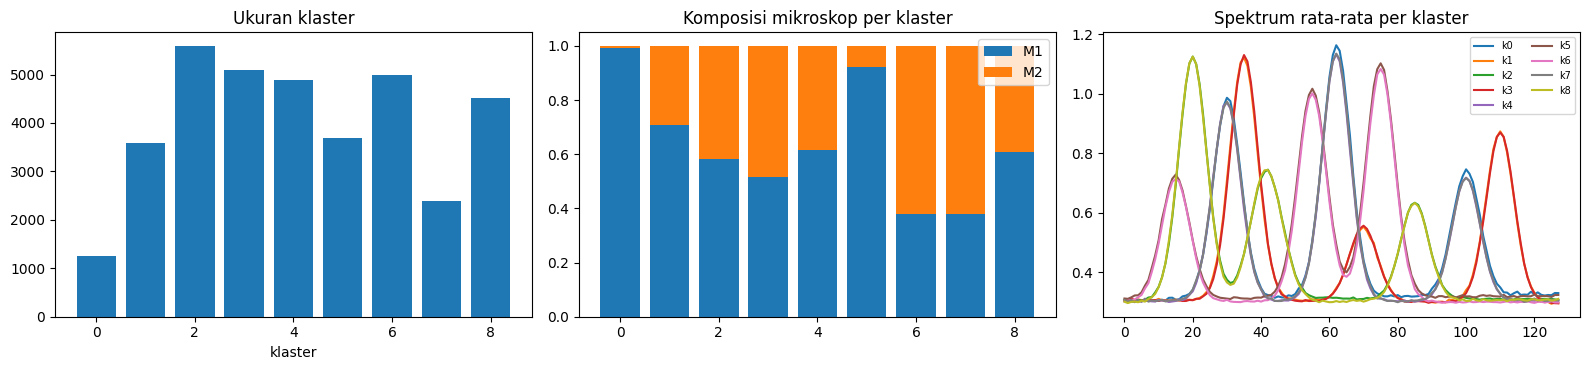

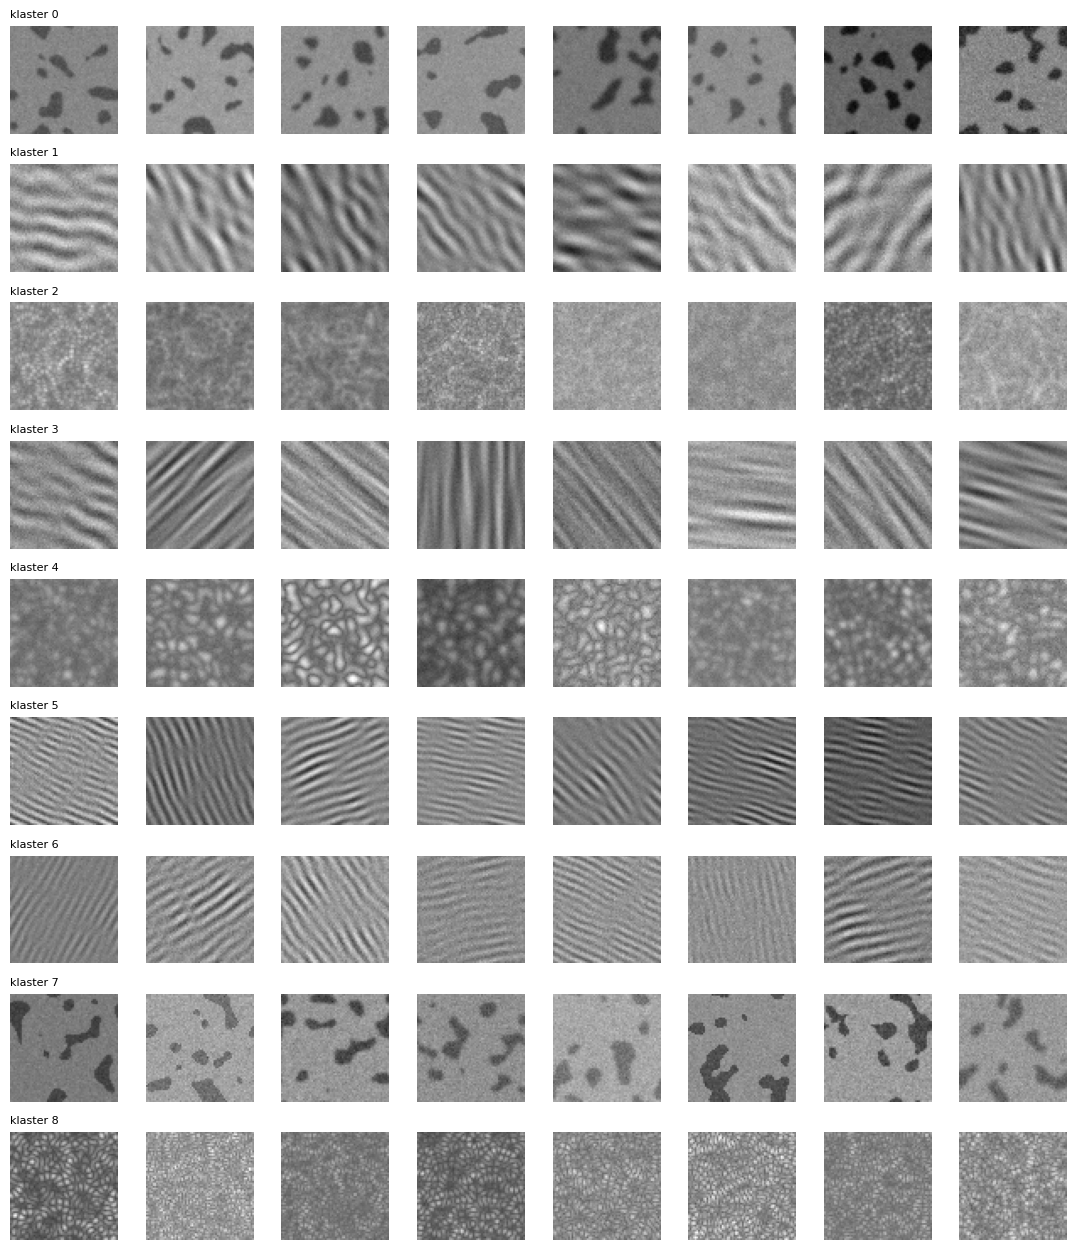

In [11]:
z = np.load('/content/data/clustering.npz')
gam, spk = z['gambar'], z['spektrum'].astype(np.float32)
K = int(len(np.unique(LABEL_FINAL)))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ukuran = np.bincount(LABEL_FINAL, minlength=K)
ax[0].bar(range(K), ukuran); ax[0].set_title("Ukuran klaster"); ax[0].set_xlabel("klaster")
mm = sorted(np.unique(mik))
bawah = np.zeros(K)
for m in mm:
    n = np.array([(mik[LABEL_FINAL == c] == m).sum() for c in range(K)]) / np.maximum(ukuran, 1)
    ax[1].bar(range(K), n, bottom=bawah, label=m); bawah += n
ax[1].set_title("Komposisi mikroskop per klaster"); ax[1].legend()
for c in range(K): ax[2].plot(spk[LABEL_FINAL == c].mean(0), label=f"k{c}")
ax[2].set_title("Spektrum rata-rata per klaster"); ax[2].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

rs_ = np.random.RandomState(0)
fig, ax = plt.subplots(K, 8, figsize=(11, 1.4 * K))
for c in range(K):
    idx = rs_.choice(np.where(LABEL_FINAL == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        ax[c, j].imshow(gam[i], cmap='gray', vmin=0, vmax=255); ax[c, j].axis('off')
    ax[c, 0].set_title(f"klaster {c}", loc='left', fontsize=8)
plt.tight_layout(); plt.show()

## 6. Visualisasi

UMAP (bila tidak dapat dipasang, t-SNE) pada 12.000 sampel acak dari embedding terpilih. Kiri: warna menurut klaster akhir. Kanan: warna menurut mikroskop.

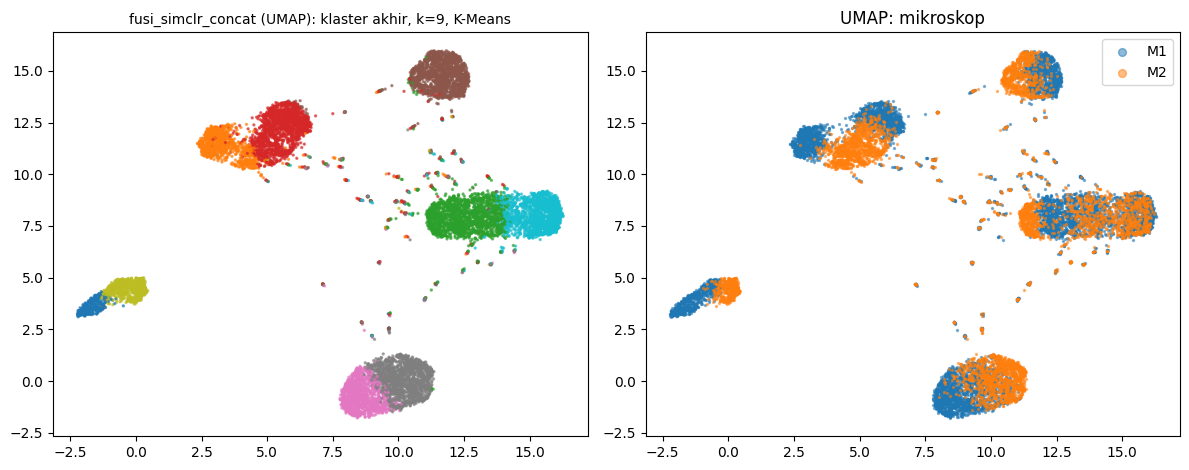

In [12]:
try:
    import umap
except ImportError:
    !pip -q install umap-learn
    try:
        import umap
    except ImportError:
        umap = None
rsub = np.random.RandomState(SEED).choice(len(mik), 12000, replace=False)
if umap is not None:
    zz, jenis = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(EMB[FINAL['representasi']][rsub]), 'UMAP'
else:
    from sklearn.manifold import TSNE
    zz, jenis = TSNE(2, init='pca', random_state=SEED).fit_transform(EMB[FINAL['representasi']][rsub]), 't-SNE'
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].scatter(zz[:, 0], zz[:, 1], c=LABEL_FINAL[rsub], s=2, cmap='tab10', alpha=0.6)
ax[0].set_title(f"{FINAL['representasi']} ({jenis}): klaster akhir, k={FINAL['k']}, {FINAL['metode']}", fontsize=10)
for m in mm:
    i = mik[rsub] == m
    ax[1].scatter(zz[i, 0], zz[i, 1], s=2, alpha=0.5, label=m)
ax[1].set_title(f"{jenis}: mikroskop"); ax[1].legend(markerscale=4)
plt.tight_layout(); plt.show()

## 7. `cluster.csv`

Berkas `cluster.csv` (kolom `id_sampel,cluster`) ditulis di akar repositori dan divalidasi: jumlah baris, keunikan ID, urutan sama dengan `clustering_meta.csv`, serta jumlah klaster dan ukuran minimum.

In [13]:
sub = pd.DataFrame({'id_sampel': meta['id_sampel'].values, 'cluster': LABEL_FINAL.astype(int)})
assert len(sub) == len(mik) == 36000 and sub.id_sampel.is_unique and sub.cluster.notna().all()
assert sub.cluster.nunique() == FINAL['k'], (sub.cluster.nunique(), FINAL['k'])
sub.to_csv(f'{REPO}/cluster.csv', index=False)
back = pd.read_csv(f'{REPO}/cluster.csv')
assert back.shape == (36000, 2) and list(back.columns) == ['id_sampel', 'cluster']
print(back.head(), "\n", back.cluster.value_counts().sort_index().to_dict())
INFO['cluster_csv'] = dict(baris=int(len(back)), jumlah_klaster=int(back.cluster.nunique()), ukuran=back.cluster.value_counts().sort_index().to_dict())

  id_sampel  cluster
0   S966119        3
1   S315633        6
2   S805122        2
3   S467543        6
4   S475842        5 
 {0: 1261, 1: 3577, 2: 5591, 3: 5098, 4: 4896, 5: 3679, 6: 4988, 7: 2394, 8: 4516}


## 8. Kesimpulan tahap 3

Teks dibangkitkan otomatis dari hasil di atas.

In [14]:
def _f(x, n=2): return f"{x:.{n}f}".replace('.', ',')

def buat_kesimpulan_t3d(info):
    p = []
    fin = info['final']
    asal = "k* dari tahap 2b" if info['k_akhir'] == info['k_star'] else f"nilai yang ditetapkan manual (k* tahap 2b = {info['k_star']})"
    p.append(f"**1. Jumlah klaster.** Jumlah klaster akhir adalah {info['k_akhir']}, yaitu {asal}. Himpunan k calon yang dievaluasi: {', '.join(map(str, info['k_set']))}.")
    tb = pd.DataFrame(info['tabel_calon'])
    banding = []
    for (rep, k), g in tb.groupby(['representasi', 'k']):
        km = g[g.metode == 'K-Means']; dd = g[g.metode == 'DEC']
        if len(km) and len(dd): banding.append(float(dd.silhouette.iloc[0] - km.silhouette.iloc[0]))
    if banding:
        naik = sum(b > 0 for b in banding)
        p.append(f"**2. DEC dibanding K-Means.** Pada {len(banding)} kombinasi (representasi × k), silhouette DEC lebih tinggi daripada K-Means pada {naik} kombinasi; selisih rata-ratanya {_f(float(np.mean(banding)), 3)}. "
                 "Silhouette dihitung pada ruang embedding asal, bukan ruang laten DEC, sehingga peningkatan tidak otomatis karena DEC mengoptimalkan ukuran itu.")
    kecil = tb[(tb.ukuran_min < 0.02)]
    if len(kecil):
        p.append(f"Pada {len(kecil)} dari {len(tb)} pelaksanaan, ada klaster yang menciut di bawah 2% data (kecenderungan runtuhnya DEC pada struktur lemah); pelaksanaan itu dikeluarkan dari pemilihan.")
    p.append(f"**3. Konfigurasi akhir.** Representasi {fin['representasi']} dengan {fin['metode']} dan k = {fin['k']} (silhouette {_f(fin['silhouette'])}, Davies-Bouldin {_f(fin['dbi'])}, keseimbangan modalitas {_f(fin['seimbang'], 3)}, NMI terhadap mikroskop {_f(fin['mik_nmi'], 3)}). "
             f"Kestabilan antar empat seed (ARI berpasangan) {_f(fin['kestabilan_seed'])}; pelabelan yang diserahkan berasal dari seed {fin['seed_medoid']} (paling mewakili).")
    if fin['kestabilan_seed'] < 0.5:
        p.append("Kestabilan antar seed di bawah 0,5, jadi pembagian akhir cukup peka terhadap inisialisasi dan sebaiknya dibaca sebagai salah satu pembagian yang masuk akal, bukan struktur yang pasti.")
    met = info['metode']; kes = met['kesesuaian']; nm = list(kes)
    pas = [(a, b, kes[a][b]) for i, a in enumerate(nm) for b in nm[i + 1:]]
    lo, hi = min(pas, key=lambda x: x[2]), max(pas, key=lambda x: x[2])
    p.append(f"**4. Metode pada konfigurasi akhir.** Kesesuaian antar lima pembagian (ARI) berkisar dari {_f(lo[2])} ({lo[0]} dan {lo[1]}) sampai {_f(hi[2])} ({hi[0]} dan {hi[1]}). "
             + ("Kesesuaian tinggi menunjukkan struktur yang sama ditemukan metode berbeda." if lo[2] >= 0.7 else "Kesesuaian tidak seragam, sehingga batas klaster bergantung pada metode."))
    ck = info['cluster_csv']
    p.append(f"**5. Keluaran.** `cluster.csv` berisi {ck['baris']} baris dengan {ck['jumlah_klaster']} klaster; ukuran klaster: {ck['ukuran']}.")
    p.append("**6. Keterbatasan.** Tidak ada label, sehingga seluruh ukuran bersifat internal dan tidak membuktikan kesesuaian dengan kelompok material sebenarnya; skor ARI terhadap label tersembunyi hanya diketahui setelah penilaian. DEC dijalankan di atas embedding tetap dari tahap 1 (encoder gambar dan spektrum tidak dilatih ulang bersama DEC). "
             "Jumlah klaster ditetapkan dari kesepakatan antar modalitas, yang mengandaikan satu kelompok laten memengaruhi gambar dan spektrum, dan kepekaan terhadap k hanya diperiksa pada beberapa nilai. Keseimbangan modalitas adalah heuristik. Hiperparameter DEC tidak disetel.")
    return '\n\n'.join(p)

KESIMPULAN = buat_kesimpulan_t3d(INFO)
display(Markdown(KESIMPULAN))

**1. Jumlah klaster.** Jumlah klaster akhir adalah 9, yaitu k* dari tahap 2b. Himpunan k calon yang dievaluasi: 7, 9, 11.

**2. DEC dibanding K-Means.** Pada 9 kombinasi (representasi × k), silhouette DEC lebih tinggi daripada K-Means pada 3 kombinasi; selisih rata-ratanya -0,028. Silhouette dihitung pada ruang embedding asal, bukan ruang laten DEC, sehingga peningkatan tidak otomatis karena DEC mengoptimalkan ukuran itu.

Pada 6 dari 27 pelaksanaan, ada klaster yang menciut di bawah 2% data (kecenderungan runtuhnya DEC pada struktur lemah); pelaksanaan itu dikeluarkan dari pemilihan.

**3. Konfigurasi akhir.** Representasi fusi_simclr_concat dengan K-Means dan k = 9 (silhouette 0,16, Davies-Bouldin 2,02, keseimbangan modalitas 0,446, NMI terhadap mikroskop 0,049). Kestabilan antar empat seed (ARI berpasangan) 0,96; pelabelan yang diserahkan berasal dari seed 1 (paling mewakili).

**4. Metode pada konfigurasi akhir.** Kesesuaian antar lima pembagian (ARI) berkisar dari 0,44 (K-Means dan Agglomerative (prototipe)) sampai 0,99 (DEC dan DEC+rek). Kesesuaian tidak seragam, sehingga batas klaster bergantung pada metode.

**5. Keluaran.** `cluster.csv` berisi 36000 baris dengan 9 klaster; ukuran klaster: {0: 1261, 1: 3577, 2: 5591, 3: 5098, 4: 4896, 5: 3679, 6: 4988, 7: 2394, 8: 4516}.

**6. Keterbatasan.** Tidak ada label, sehingga seluruh ukuran bersifat internal dan tidak membuktikan kesesuaian dengan kelompok material sebenarnya; skor ARI terhadap label tersembunyi hanya diketahui setelah penilaian. DEC dijalankan di atas embedding tetap dari tahap 1 (encoder gambar dan spektrum tidak dilatih ulang bersama DEC). Jumlah klaster ditetapkan dari kesepakatan antar modalitas, yang mengandaikan satu kelompok laten memengaruhi gambar dan spektrum, dan kepekaan terhadap k hanya diperiksa pada beberapa nilai. Keseimbangan modalitas adalah heuristik. Hiperparameter DEC tidak disetel.

## 9. Commit ke branch `task3-dec`

Setelah sel ini, simpan notebook dengan **File → Save a copy in GitHub** (repositori fork, branch `task3-dec`, path `kode/task3_cluster/task3_dec.ipynb`), lalu buka *pull request* ke repositori organisasi.

In [15]:
with open(f'{OUT}/hasil/task3_dec.json', 'w') as f: json.dump({'info': INFO}, f, indent=2, default=float)
with open(f'{OUT}/hasil/kesimpulan_task3_dec.md', 'w') as f: f.write(KESIMPULAN)
np.save(f"{OUT}/hasil/label_final.npy", LABEL_FINAL.astype(np.int16))
%cd /content/UTSDEEPLEARNING
!git add cluster.csv kode/task3_cluster/clu_cluster.py kode/task3_cluster/clu_dec.py kode/task3_cluster/hasil
!git commit -m "Task 3 tahap 3: DEC, pemilihan konfigurasi akhir, cluster.csv"
!git push origin task3-dec

/content/UTSDEEPLEARNING
[task3-dec ca144f5] Task 3 tahap 3: DEC, pemilihan konfigurasi akhir, cluster.csv
 9 files changed, 36825 insertions(+)
 create mode 100644 cluster.csv
 create mode 100644 kode/task3_cluster/clu_dec.py
 create mode 100644 kode/task3_cluster/hasil/dec_kesesuaian_metode.csv
 create mode 100644 kode/task3_cluster/hasil/dec_perbandingan_metode.csv
 create mode 100644 kode/task3_cluster/hasil/dec_semua_calon.csv
 create mode 100644 kode/task3_cluster/hasil/kesimpulan_task3_dec.md
 create mode 100644 kode/task3_cluster/hasil/label_final.npy
 create mode 100644 kode/task3_cluster/hasil/task3_dec.json
Enumerating objects: 19, done.
Counting objects: 100% (19/19), done.
Delta compression using up to 2 threads
Compressing objects: 100% (14/14), done.
Writing objects: 100% (14/14), 177.13 KiB | 3.69 MiB/s, done.
Total 14 (delta 6), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (6/6), completed with 5 local objects.
remote: 
remote: Create a pull request